In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("./diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# `get_clf_eval`은 실제 정답과 예측 결과를 받아 분류 성능 지표를 출력하도록 만든 함수입니다.

def get_clf_eval(y_test, pred = None , pred_proba = None): # 종합평가함수 (오차행렬 , 정확도 , 정밀도 , 재현율)
    confusion = confusion_matrix(y_test,pred)
    accuracy = accuracy_score(y_test,pred)
    precision = precision_score(y_test,pred)
    recall = recall_score(y_test,pred)
    f1 = f1_score(y_test , pred)
    rod_auc = roc_auc_score(y_test,pred_proba)

    print("오차행렬")
    print(confusion)
    print("정확도",accuracy)
    print("정밀도",precision)
    print("재현율",recall)
    print("f1",f1)
    print("roc_auc",rod_auc)

In [4]:
# `iloc`은 행과 열을 번호로 선택합니다. `[:, :-1]`은 모든 행과 마지막 열을 뺀 입력 특성 X입니다.
# `[:, -1]`은 마지막 열 전체를 정답 y로 선택합니다. 이 데이터에서는 Outcome이 당뇨 여부입니다.
# `value_counts()`는 Outcome의 각 값(예: 0, 1)이 몇 번 나오는지 셉니다.
X = df.iloc[: , :-1]
y = df.iloc [ : ,-1]

df["Outcome"].value_counts()

0    500
1    268
Name: Outcome, dtype: int64

In [5]:
# 데이터를 학습 세트와 테스트 세트로 나눕니다. 학습 세트로 모델을 맞추고 테스트 세트로 성능을 확인합니다.
# `test_size=0.2`는 20%를 테스트에 사용합니다. `random_state`는 나눔 결과를 재현 가능하게 고정합니다.
# `stratify=y`는 두 세트에서 Outcome의 0/1 비율이 비슷하게 유지되도록 합니다.
X_train , X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42,stratify= y)

In [6]:
# 로지스틱 회귀 분류기를 만들고 학습용 데이터와 정답으로 학습합니다.
# `predict`는 테스트 데이터의 0/1 분류 결과를 반환합니다. predict_prova는 각 클래스에 속할 확률을 예측 (분류를 퍼센트로 예측)
# 아래 호출은 실제 정답, 예측 라벨, 양성 클래스 확률을 평가 함수에 전달하는 구조입니다.
lr_clf = LogisticRegression(solver='liblinear')
lr_clf.fit(X_train,y_train)
pred = lr_clf.predict(X_test)
pred_proba = lr_clf.predict(X_test)

get_clf_eval(y_test, pred, pred_proba)

오차행렬
[[85 15]
 [27 27]]
정확도 0.7272727272727273
정밀도 0.6428571428571429
재현율 0.5
f1 0.5625000000000001
roc_auc 0.6749999999999999


In [7]:
# `describe()`는 숫자 열마다 개수, 평균, 표준편차, 최솟값, 사분위수, 최댓값을 요약합니다.
# 이 요약을 보면 값의 범위나 이상하게 큰/작은 값이 있는지 살펴볼 수 있습니다.
df. describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


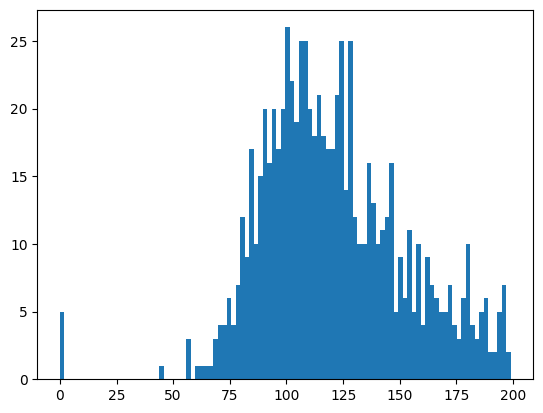

In [8]:
# Glucose(혈당) 값의 분포를 히스토그램으로 그립니다.
# `bins=100`은 전체 범위를 100개의 구간으로 나눠 빈도를 표시한다는 뜻입니다.
# `show()`는 만든 그래프를 화면에 출력합니다.
plt.hist(df["Glucose"],bins=100)
plt.show()

In [9]:
# 이 데이터에서는 일부 측정 열의 0이 실제 측정값이 아니라 미입력 표시일 수 있어 열 목록을 정합니다.
zero_features = ["Glucose", "BloodPressure","SkinThickness","Insulin","BMI"]

# 전체 행 수를 세고, 각 열에서 값이 0인 행의 수와 전체 중 비율을 출력합니다.
# `df[조건]`은 조건을 만족하는 행만 골라내며, `.count()`는 해당 열의 값 개수를 셉니다.
total_count = df["Glucose"].count()
for feature in zero_features : 
    zero_count = df[df[feature]==0][feature].count()
    print(feature,zero_count, 100*zero_count/total_count,"%")

Glucose 5 0.6510416666666666 %
BloodPressure 35 4.557291666666667 %
SkinThickness 227 29.557291666666668 %
Insulin 374 48.697916666666664 %
BMI 11 1.4322916666666667 %


In [ ]:
# 학습/테스트로 나누기 전에 전체 데이터에 맞추면 테스트 데이터 정보가 학습 과정에 섞일 수 있습니다. 일반적으로는 학습 데이터에만 fit한 뒤 양쪽을 transform합니다.
# 다음 줄은 변환된 데이터를 다시 학습/테스트 세트로 나누고, 모델을 학습한 뒤 예측합니다.
# 같은 평가 함수를 연달아 두 번 호출하면 동일한 결과가 두 번 출력됩니다.

# StandardScaler는 각 특성을 평균 0, 표준편차 1에 가까운 척도로 바꿉니다. 값 범위가 다른 특성들을 비교하기 쉬워집니다.
scaler = StandardScaler()

# fit 또는 fit_transform은 딱 한번만 쓸 수 있음 : 재학습의 경 재사용 가능
# X_train에 fit했으면 , X_train는 무조건 transform만 해야함


# `fit_transform(X)`는 전체 X에서 평균/표준편차를 계산(fit)한 뒤 변환(transform)합니다.
X_scaled = scaler.fit_transform(X) #특성 X 전체에서 평균과 표준편차를 계산하고, 그 기준으로 값을 변환

# Standardscaler가 항상 성능을 높여 주는 건 아니지만, 
# 숫자 범위가 크게 다른 특성들을 쓰는 모델이 안정적으로 학습하도록 도와줄 수 있음

X_train, X_test, y_train, y_test = train_test_split(X_scaled,y , test_size= 0.2, random_state= 42, stratify =y)

# 스케일링후 재학습
lr_clf.fit(X_train,y_train) #로지스터 회귀모델
pred = lr_clf.predict(X_test)

pred_proba = lr_clf.predict_proba(X_test)[:, 1] 
# `predict_proba(... )[:, 1]`은 각 행이 클래스 1일 확률만 뽑습니다. 평가 함수에 라벨과 확률을 전달합니다.

get_clf_eval(y_test, pred , pred_proba)



오차행렬
[[82 18]
 [26 28]]
정확도 0.7142857142857143
정밀도 0.6086956521739131
재현율 0.5185185185185185
f1 0.5599999999999999
roc_auc 0.8229629629629629
